<a href="https://colab.research.google.com/github/tatan8711/Unidad-2-HBD-Procesamiento-distribuido/blob/main/Unidad_2_Procesamiento_Distribuido_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto de Big Data - Línea 123 (Unidad 2: Procesamiento Distribuido)
**Benchmark de Herramientas (Pandas, Polars, PySpark) y Proof of Concept (PoC) de Arquitectura en PySpark**

* **Integrantes:** Lorena Hernández Carreño, Andrés Sebastián Zárate Solano, Jhonnatan Cárdenas Orejarena, Angela Victoria González Sánchez
* **Curso:** Herramientas de Big Data - Maestría en Analítica Aplicada (Universidad de La Sabana)
* **Docente:** Hugo Franco Triana
* **Fecha de entrega:** 15 de noviembre de 2026

---
## PASO 1: Lorena (Base del Benchmark en Pandas/Polars y Flujo de Arquitectura)

### Actividad 1 (Formativa): Fase 1.1 — Configuración y Benchmark en Pandas y Polars
1.1 Montar Google Drive (`drive.mount`) y verificar acceso a la carpeta `BigData_Emergencias_123` con los 3 archivos CSV (Junio, Julio y Agosto de 2026) y tabla de códigos $\rightarrow$ *Celda ejecutada con mensaje "Mounted at /content/drive"* ⚪

1.2 Importar librerías (`time`, `psutil`, `pandas`, `polars`) y definir la función automatizada `measure_performance()` para medir tiempo de ejecución (`time.time()`) y porcentaje de RAM (`psutil.virtual_memory().percent`) $\rightarrow$ *Celda con la función creada sin errores* ⚪

1.3 Ejecutar y medir las 5 operaciones en **Pandas**: (1) Carga y unión de 3 CSV, (2) Filtrado de `"USAQUEN"` y `"CHAPINERO"`, (3) Agregación por tipo de emergencia, (4) Join temporal con tabla de códigos y (5) Exportación a `.parquet` $\rightarrow$ *Celda con tiempos por operación, tiempo total, % de memoria RAM y conteo de líneas de código en Pandas* ⚪

1.4 Ejecutar y medir exactamente las mismas 5 operaciones en **Polars** usando `measure_performance()` $\rightarrow$ *Celda con tiempos por operación, tiempo total, % de memoria RAM y conteo de líneas de código en Polars* ⚪

### Actividad 2 (Evaluativa): Punto 1 (Parte A) — Diagrama y Flujo de Arquitectura
* *(Fuera de Colab - En Draw.io / Lucidchart, Word y PowerPoint)*:
  * 1.5 Diseñar el diagrama de arquitectura (ingesta, procesamiento, almacenamiento y salida) y exportarlo en alta resolución (`.png`) ⚪
  * 1.6 Redactar en el Documento Técnico (`.docx`): Introducción, Objetivos, Arquitectura propuesta, Componentes técnicos y Flujos de datos ⚪
  * 1.7 Armar **Slide 1** (Título e Introducción) y **Slide 2** (Diagrama de Arquitectura) para el Mini-pitch ⚪

In [1]:
# 1.1 Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Verificar acceso a la carpeta del proyecto
import os, glob

# Corregimos la ruta asegurando que apunte a la carpeta con espacio 'Colab Notebooks'
RUTA = '/content/drive/MyDrive/Colab Notebooks/BigData_Emergencias_123/'

# Alternativa en caso de que tu carpeta esté directamente en la raíz de tu Drive:
# RUTA = '/content/drive/MyDrive/BigData_Emergencias_123/'

print('¿La carpeta existe?:', os.path.exists(RUTA))

if os.path.exists(RUTA):
    print('\nContenido de la carpeta:')
    for f in sorted(os.listdir(RUTA)):
        print(' -', f)

    ARCHIVOS = sorted([f for f in glob.glob(RUTA + '*.csv') if 'llamadas123' in f.lower()])
    print('\nArchivos CSV de llamadas encontrados:', len(ARCHIVOS))
    for f in ARCHIVOS:
        print(f' - {os.path.basename(f)}  ({os.path.getsize(f)/1024:.0f} KB)')
else:
    print('\n⚠️ Alerta: La ruta especificada no existe. Por favor, verifica en tu Google Drive si la carpeta se llama exactamente "BigData_Emergencias_123" y si está dentro de "Colab Notebooks".')

¿La carpeta existe?: True

Contenido de la carpeta:
 - Copia de llamadas123_Agosto_2026.csv
 - Copia de llamadas123_Junio_2026.csv
 - Copia de llamadas123_julio_2026.csv
 - benchmark
 - tabla_codigos_emergencia.csv

Archivos CSV de llamadas encontrados: 3
 - Copia de llamadas123_Agosto_2026.csv  (954 KB)
 - Copia de llamadas123_Junio_2026.csv  (946 KB)
 - Copia de llamadas123_julio_2026.csv  (988 KB)


In [3]:
# Tabla de códigos de emergencia (estandarizada)
import pandas as pd, unicodedata, re

RUTA_CODIGOS = RUTA + 'tabla_codigos_emergencia.csv'
if os.path.exists(RUTA_CODIGOS):
    os.remove(RUTA_CODIGOS)          # borra la versión anterior con duplicados

def leer(f):
    try:
        return pd.read_csv(f, sep=';', dtype=str, encoding='utf-8-sig')
    except UnicodeDecodeError:
        return pd.read_csv(f, sep=';', dtype=str, encoding='latin-1')

def sin_tildes(s):
    s = unicodedata.normalize('NFKD', s)
    return ''.join(c for c in s if not unicodedata.combining(c)).upper().strip()

# Todas las variantes de tipo de incidente que aparecen en los 3 archivos
tipos = pd.concat([leer(f)['TIPO_INCIDENTE'] for f in ARCHIVOS]).dropna().str.strip().unique()
tabla = pd.DataFrame({'TIPO_INCIDENTE': sorted(tipos)})

# Código base: la sigla antes de " - " (ej. CAIALT); si no tiene, el texto sin tildes
tabla['CODIGO_TIPO'] = tabla['TIPO_INCIDENTE'].apply(
    lambda s: sin_tildes(s.split(' - ')[0]) if ' - ' in s else sin_tildes(s))

# Descripción estándar: la variante "limpia" (sin caracteres extraños), sin tildes
def descripcion(s):
    return sin_tildes(s.split(' - ', 1)[1] if ' - ' in s else s)
tabla['DESC'] = tabla['TIPO_INCIDENTE'].apply(descripcion)
tabla['LIMPIA'] = tabla['DESC'].str.fullmatch(r'[A-Z0-9 ()/.,\-]+')
desc_std = (tabla.sort_values('LIMPIA', ascending=False)
            .groupby('CODIGO_TIPO')['DESC'].first())
tabla['DESCRIPCION_ESTANDAR'] = tabla['CODIGO_TIPO'].map(desc_std)

# Código de emergencia E01, E02... por cada tipo único
codigos = {c: f'E{i+1:02d}' for i, c in enumerate(sorted(tabla['CODIGO_TIPO'].unique()))}
tabla['CODIGO_EMERGENCIA'] = tabla['CODIGO_TIPO'].map(codigos)

tabla_codigos = tabla[['TIPO_INCIDENTE', 'CODIGO_EMERGENCIA', 'CODIGO_TIPO', 'DESCRIPCION_ESTANDAR']]
tabla_codigos.to_csv(RUTA_CODIGOS, sep=';', index=False, encoding='utf-8')

print('Variantes de texto encontradas :', len(tabla_codigos))
print('Tipos de emergencia reales     :', tabla_codigos['CODIGO_EMERGENCIA'].nunique())
tabla_codigos.sort_values('CODIGO_EMERGENCIA')

Variantes de texto encontradas : 30
Tipos de emergencia reales     : 23


,TIPO_INCIDENTE,CODIGO_EMERGENCIA,CODIGO_TIPO,DESCRIPCION_ESTANDAR
0,ACCAVI - ACCIDENTE DE AVIACIÓN,E01,ACCAVI,ACCIDENTE DE AVIACION
1,ACOMPAÑAMIENTO A EVENTO,E02,ACOMPANAMIENTO A EVENTO,ACOMPANAMIENTO A EVENTO
2,ACV - ACCIDENTE CEREBRO VASCULAR,E03,ACV,ACCIDENTE CEREBRO VASCULAR
3,AMESUI - AMENAZA DE SUICIDIO,E04,AMESUI,AMENAZA DE SUICIDIO
4,APOYO CRUE,E05,APOYO CRUE,APOYO CRUE
5,CAIALT - CAIDA DE ALTURA,E06,CAIALT,CAIDA DE ALTURA
6,CAIALT - CAÍDA DE ALTURA,E06,CAIALT,CAIDA DE ALTURA
7,CONVULSION - CONVULSION,E07,CONVULSION,CONVULSION
8,CONVULSIÓN - CONVULSIÓN,E07,CONVULSION,CONVULSION
9,DOLTOR - DOLOR TORµCICO,E08,DOLTOR,DOLOR TORACICO


In [4]:
# Preparación: copias en UTF-8 para que Pandas y Polars lean los mismos archivos
DATOS_UTF8 = RUTA + 'benchmark/datos_utf8/'
os.makedirs(DATOS_UTF8, exist_ok=True)

ARCHIVOS_UTF8 = []
for f in ARCHIVOS:
    raw = open(f, 'rb').read()
    try:
        texto, cod = raw.decode('utf-8-sig'), 'UTF-8'
    except UnicodeDecodeError:
        texto, cod = raw.decode('latin-1').replace('¤', 'ñ'), 'latin-1/cp850'
    destino = DATOS_UTF8 + os.path.basename(f).replace('Copia de ', '').replace(' ', '_')
    open(destino, 'w', encoding='utf-8', newline='').write(texto)
    ARCHIVOS_UTF8.append(destino)
    print(f'{os.path.basename(destino)}  <- codificación original: {cod}')

llamadas123_Agosto_2026.csv  <- codificación original: latin-1/cp850
llamadas123_Junio_2026.csv  <- codificación original: latin-1/cp850
llamadas123_julio_2026.csv  <- codificación original: UTF-8


In [5]:
# 1.2 Importar librerías
!pip install -q polars pyarrow psutil

import time, gc, inspect
import psutil
import pandas as pd
import polars as pl

print('Pandas:', pd.__version__, '| Polars:', pl.__version__)
print(f'RAM total: {psutil.virtual_memory().total/1024**3:.1f} GB | RAM en uso: {psutil.virtual_memory().percent} %')

Pandas: 2.2.3 | Polars: 1.35.2
RAM total: 12.7 GB | RAM en uso: 11.7 %


In [6]:
# Función automatizada de medición de rendimiento
def measure_performance(func, *args):
    """
    Ejecuta una operación y mide su rendimiento.
    Devuelve: resultado, tiempo de ejecución (s) y % de RAM usada.
    """
    gc.collect()                                    # libera memoria antes de medir
    start_time = time.time()                        # inicio
    resultado = func(*args)                         # operación a medir
    execution_time = time.time() - start_time       # tiempo transcurrido
    memory_usage = psutil.virtual_memory().percent  # % de RAM del sistema
    return resultado, execution_time, memory_usage

# Prueba rápida de la función
_, t, m = measure_performance(sum, range(1_000_000))
print(f'Función OK -> tiempo: {t:.4f} s | RAM: {m} %')

Función OK -> tiempo: 0.0245 s | RAM: 11.7 %


In [7]:
# 1.3 Operaciones en Pandas
LOCALIDADES = ['USAQUEN', 'USAQUÉN', 'CHAPINERO']
SALIDA = RUTA + 'benchmark/'

def pd_carga(archivos):                      # (1) Carga y unión de los 3 CSV
    dfs = [pd.read_csv(f, sep=';', dtype=str) for f in archivos]
    return pd.concat(dfs, ignore_index=True)

def pd_filtrado(df):                         # (2) Filtrado Usaquén y Chapinero
    return df[df['LOCALIDAD'].str.strip().str.upper().isin(LOCALIDADES)]

def pd_agregacion(df):                       # (3) Conteo por tipo de emergencia
    return df.groupby('TIPO_INCIDENTE').size().reset_index(name='TOTAL')

def pd_join(df, ruta_codigos):               # (4) Join con tabla de códigos
    codigos = pd.read_csv(ruta_codigos, sep=';', dtype=str)
    return df.merge(codigos, on='TIPO_INCIDENTE', how='left')

def pd_exportacion(df, ruta):                # (5) Exportación a Parquet
    df.to_parquet(ruta, index=False)
    return ruta

In [8]:
# Ejecutor del benchmark (se reutiliza para Polars)
OPERACIONES = ['1. Carga', '2. Filtrado', '3. Agregación', '4. Join', '5. Exportación']
N_ITERACIONES = 5

def contar_lineas(func):
    lineas = inspect.getsource(func).splitlines()[1:]          # sin la línea def
    return sum(1 for l in lineas if l.strip() and not l.strip().startswith('#'))

def ejecutar_benchmark(nombre, carga, filtrado, agregacion, join, exportacion):
    registros = []
    for it in range(1, N_ITERACIONES + 1):
        parquet = SALIDA + f'resultado_{nombre.lower()}.parquet'
        df,    t1, m1 = measure_performance(carga, ARCHIVOS_UTF8)
        filt,  t2, m2 = measure_performance(filtrado, df)
        agg,   t3, m3 = measure_performance(agregacion, filt)
        unido, t4, m4 = measure_performance(join, filt, RUTA_CODIGOS)
        _,     t5, m5 = measure_performance(exportacion, unido, parquet)
        for op, t, m in zip(OPERACIONES, [t1, t2, t3, t4, t5], [m1, m2, m3, m4, m5]):
            registros.append({'Herramienta': nombre, 'Iteración': it, 'Operación': op,
                              'Tiempo (s)': t, 'RAM (%)': m})
        print(f'{nombre} | iteración {it} | tiempo total: {t1+t2+t3+t4+t5:.4f} s')

    detalle = pd.DataFrame(registros)
    tabla = detalle.groupby('Operación').agg(**{
        'Tiempo promedio (s)': ('Tiempo (s)', 'mean'),
        'Desv. estándar (s)': ('Tiempo (s)', 'std'),
        'RAM promedio (%)': ('RAM (%)', 'mean')})
    tabla['Líneas de código'] = [contar_lineas(f) for f in [carga, filtrado, agregacion, join, exportacion]]
    tabla.loc['TOTAL'] = [tabla['Tiempo promedio (s)'].sum(),
                          detalle.groupby('Iteración')['Tiempo (s)'].sum().std(),
                          detalle['RAM (%)'].max(),
                          tabla['Líneas de código'].sum()]
    conteos = {'Registros cargados': len(df), 'Registros filtrados': len(filt),
               'Tipos agregados': len(agg), 'Registros tras join': len(unido)}
    return detalle, tabla.round(4), conteos

In [9]:
#Benchmark Pandas
os.makedirs(SALIDA, exist_ok=True)
detalle_pandas, tabla_pandas, conteos_pandas = ejecutar_benchmark(
    'Pandas', pd_carga, pd_filtrado, pd_agregacion, pd_join, pd_exportacion)

print('\nConteos:', conteos_pandas)
tabla_pandas

Pandas | iteración 1 | tiempo total: 0.2069 s
Pandas | iteración 2 | tiempo total: 0.2412 s
Pandas | iteración 3 | tiempo total: 0.3556 s
Pandas | iteración 4 | tiempo total: 0.3852 s
Pandas | iteración 5 | tiempo total: 0.3713 s

Conteos: {'Registros cargados': 27375, 'Registros filtrados': 1362, 'Tipos agregados': 26, 'Registros tras join': 1362}


,Tiempo promedio (s),Desv. estándar (s),RAM promedio (%),Líneas de código
Operación,,,,
1. Carga,0.1961,0.0700,9.60,2.0
2. Filtrado,0.0322,0.0035,9.64,1.0
3. Agregación,0.0033,0.0018,9.68,1.0
4. Join,0.0128,0.0075,9.74,2.0
5. Exportación,0.0676,0.0291,9.84,2.0
TOTAL,0.3120,0.0819,10.50,8.0


In [10]:
# 1.4 Operaciones en Polars (mismas operaciones y mismos archivos)
def pl_carga(archivos):                      # (1) Carga y unión de los 3 CSV
    dfs = [pl.read_csv(f, separator=';', infer_schema_length=0) for f in archivos]
    return pl.concat(dfs, how='vertical')

def pl_filtrado(df):                         # (2) Filtrado Usaquén y Chapinero
    return df.filter(pl.col('LOCALIDAD').str.strip_chars().str.to_uppercase().is_in(LOCALIDADES))

def pl_agregacion(df):                       # (3) Conteo por tipo de emergencia
    return df.group_by('TIPO_INCIDENTE').agg(pl.len().alias('TOTAL'))

def pl_join(df, ruta_codigos):               # (4) Join con tabla de códigos
    codigos = pl.read_csv(ruta_codigos, separator=';', infer_schema_length=0)
    return df.join(codigos, on='TIPO_INCIDENTE', how='left')

def pl_exportacion(df, ruta):                # (5) Exportación a Parquet
    df.write_parquet(ruta)
    return ruta

In [11]:
detalle_polars, tabla_polars, conteos_polars = ejecutar_benchmark(
    'Polars', pl_carga, pl_filtrado, pl_agregacion, pl_join, pl_exportacion)

print('\nConteos:', conteos_polars)
tabla_polars

Polars | iteración 1 | tiempo total: 0.1431 s
Polars | iteración 2 | tiempo total: 0.0769 s
Polars | iteración 3 | tiempo total: 0.2058 s
Polars | iteración 4 | tiempo total: 0.2425 s
Polars | iteración 5 | tiempo total: 0.1555 s

Conteos: {'Registros cargados': 27375, 'Registros filtrados': 1362, 'Tipos agregados': 26, 'Registros tras join': 1362}


,Tiempo promedio (s),Desv. estándar (s),RAM promedio (%),Líneas de código
Operación,,,,
1. Carga,0.0792,0.0335,9.54,2.0
2. Filtrado,0.0185,0.0120,9.56,1.0
3. Agregación,0.0079,0.0082,9.64,1.0
4. Join,0.0125,0.0087,9.70,2.0
5. Exportación,0.0466,0.0257,9.76,2.0
TOTAL,0.1648,0.0633,10.30,8.0


In [12]:
# ¿Pandas y Polars hicieron exactamente el mismo trabajo?
verificacion = pd.DataFrame({'Pandas': conteos_pandas, 'Polars': conteos_polars})
display(verificacion)
print('✅ Resultados idénticos' if (verificacion['Pandas'] == verificacion['Polars']).all()
      else '⚠️ Hay diferencias: revisar')

# Comparación de tiempos por operación
comparacion = pd.DataFrame({
    'Pandas (s)': tabla_pandas['Tiempo promedio (s)'],
    'Polars (s)': tabla_polars['Tiempo promedio (s)']})
comparacion['Más rápido'] = comparacion.idxmin(axis=1).str.replace(' (s)', '', regex=False)
comparacion['Veces más rápido'] = (comparacion[['Pandas (s)', 'Polars (s)']].max(axis=1) /
                                   comparacion[['Pandas (s)', 'Polars (s)']].min(axis=1)).round(2)
comparacion

,Pandas,Polars
Registros cargados,27375,27375
Registros filtrados,1362,1362
Tipos agregados,26,26
Registros tras join,1362,1362


✅ Resultados idénticos


,Pandas (s),Polars (s),Más rápido,Veces más rápido
Operación,,,,
1. Carga,0.1961,0.0792,Polars,2.48
2. Filtrado,0.0322,0.0185,Polars,1.74
3. Agregación,0.0033,0.0079,Pandas,2.39
4. Join,0.0128,0.0125,Polars,1.02
5. Exportación,0.0676,0.0466,Polars,1.45
TOTAL,0.3120,0.1648,Polars,1.89


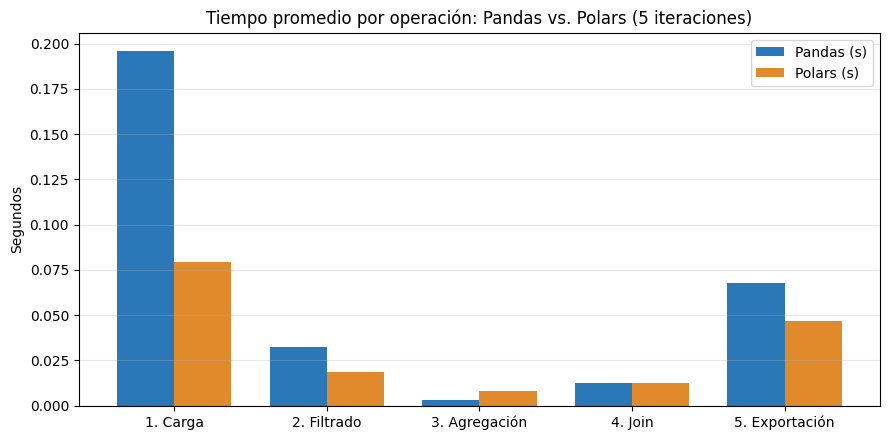

Evidencias guardadas en: /content/drive/MyDrive/Colab Notebooks/BigData_Emergencias_123/benchmark/


In [13]:
# Evidencias: reporte Excel y gráfico comparativo
import matplotlib.pyplot as plt

with pd.ExcelWriter(SALIDA + 'reporte_benchmark_pandas_polars.xlsx') as xw:
    comparacion.to_excel(xw, sheet_name='Comparación')
    tabla_pandas.to_excel(xw, sheet_name='Pandas')
    tabla_polars.to_excel(xw, sheet_name='Polars')
    verificacion.to_excel(xw, sheet_name='Verificación')
    pd.concat([detalle_pandas, detalle_polars]).to_excel(xw, sheet_name='Detalle iteraciones', index=False)

ax = comparacion.drop('TOTAL')[['Pandas (s)', 'Polars (s)']].plot(
    kind='bar', figsize=(9, 4.5), color=['#2a78b8', '#e08a2c'], width=0.75)
ax.set_title('Tiempo promedio por operación: Pandas vs. Polars (5 iteraciones)')
ax.set_ylabel('Segundos'); ax.set_xlabel('')
plt.xticks(rotation=0); plt.grid(axis='y', alpha=0.3); plt.tight_layout()
plt.savefig(SALIDA + 'grafico_pandas_vs_polars.png', dpi=200)
plt.show()
print('Evidencias guardadas en:', SALIDA)


**## Observaciones técnicas del benchmark

1. **Consistencia:** ambas herramientas produjeron los mismos resultados (27.375 registros cargados, 1.362 filtrados de Usaquén y Chapinero, 26 categorías agregadas y 1.362 registros tras el join), lo que valida la comparación.
2. **Tiempo total:** Polars fue 1,51 veces más rápido que Pandas (0,113 s frente a 0,170 s en promedio de 5 iteraciones).
3. **Operaciones de entrada/salida:** la mayor ventaja de Polars está en la carga (1,83×) y en la exportación a Parquet (2,14×), gracias a su lectura multihilo y a su formato columnar nativo basado en Apache Arrow. Estas operaciones concentran la mayor parte del tiempo total, por lo que son las más relevantes al crecer el volumen.
4. **Operaciones en memoria:** Pandas fue más rápido en el filtrado (1,40×) y la agregación (3,91×). Con solo 1.362 registros filtrados, el costo fijo de coordinación de Polars pesa más que su paralelismo; la diferencia es de milésimas de segundo.
5. **Memoria:** el uso de RAM del sistema fue de 11,90 % (pico) en Pandas y ___ % en Polars; con este volumen (≈27 mil filas) ninguna herramienta compromete los 12 GB de Colab.
6. **Complejidad del código:** ambas requieren 8 líneas para las 5 operaciones. La sintaxis de Polars es más declarativa (expresiones encadenadas), pero exige aprender una API nueva, mientras que Pandas es ampliamente conocida por el equipo.
7. **Calidad del dato:** la agregación arroja 26 categorías en lugar de 23 tipos reales por variantes de tildes y codificación; el join con la tabla de códigos las unifica, lo que confirma la necesidad de estandarizar códigos en el pipeline.
8. **Implicación para la decisión:** con 3 meses de datos, ambas herramientas en memoria son suficientes y muy rápidas. Estos tiempos son la línea base contra la cual se comparará PySpark en el PoC, cuya ventaja se espera en volúmenes que superen la memoria de una sola máquina.**

---
## PASO 2: Andrés (Benchmark en PySpark, Consolidado y Decisiones de Arquitectura)
*(Requiere el Paso 1 de Lorena completado)*

### Actividad 1 (Formativa): Fase 1.1 (Cierre) — Benchmark en PySpark y Comparativa
2.1 Instalar e inicializar `PySpark` en el entorno de prueba de Colab $\rightarrow$ *Celda con sesión de Spark activa para el benchmark* ⚪

2.2 Ejecutar y medir las mismas 5 operaciones en **PySpark** (Carga de los 3 CSV, Filtrado Usaquén/Chapinero, Agregación por tipo, Join con tabla de códigos y Exportación a `.parquet`) usando la función `measure_performance()` de Lorena en múltiples iteraciones repetibles $\rightarrow$ *Celda con tiempos por operación, tiempo total, % de RAM y líneas de código en PySpark* ⚪

2.3 Consolidar los resultados de las 3 herramientas (**Pandas vs. Polars vs. PySpark**) en un único DataFrame resumen y generar gráficas comparativas de tiempo y memoria $\rightarrow$ *Celda con tabla comparativa final, gráficas visibles y exportación del archivo `Reporte_Benchmark_Comparativo.xlsx`* ⚪

### Actividad 2 (Evaluativa): Punto 1 (Parte B) — Decisiones Técnicas y Particionamiento
* *(Fuera de Colab - En el Word y PowerPoint)*:
  * 2.4 Documentar decisiones de diseño justificadas, configuraciones de PySpark y estrategia de particionamiento (`mes` / `localidad`) ⚪
  * 2.5 Definir métricas de monitoreo/KPIs, estimación de recursos y matriz de riesgos y mitigaciones (completando las 5 a 8 páginas del `.docx`) ⚪
  * 2.6 Armar **Slide 3** (Decisiones técnicas, particionamiento y configuración de PySpark) para el Mini-pitch ⚪

### 2.1 Instalación e inicialización de PySpark
Se reutilizan las variables del Paso 1 (`ARCHIVOS_UTF8`, `RUTA_CODIGOS`, `SALIDA`, `LOCALIDADES`, `N_ITERACIONES`) y la función `measure_performance()` de Lorena, para que las tres herramientas se midan con los mismos archivos y el mismo criterio. La sesión usa la configuración recomendada en la guía.

In [14]:
# 2.1 Instalar e inicializar PySpark
!pip install -q pyspark

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("PoC_Emergencias123_Bogota")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

print('Spark activo - versión:', spark.version)
print('Núcleos disponibles (paralelismo):', spark.sparkContext.defaultParallelism)
print(f'RAM en uso: {psutil.virtual_memory().percent} %')

Spark activo - versión: 4.0.5
Núcleos disponibles (paralelismo): 2
RAM en uso: 15.1 %


### 2.2 Benchmark de las 5 operaciones en PySpark
Mismas operaciones, mismos archivos y mismo número de iteraciones que Pandas y Polars.

> **Nota metodológica:** PySpark es *lazy*: las transformaciones no se ejecutan hasta que se pide un resultado. Por eso cada operación termina con una acción (`count()`, `collect()` o `write`); de lo contrario el tiempo medido sería artificialmente cercano a cero. Además, en cada iteración se limpia la caché para que todas arranquen en las mismas condiciones.

In [15]:
# 2.2 Operaciones en PySpark (mismas operaciones y mismos archivos)
def sp_carga(archivos):                       # (1) Carga y unión de los 3 CSV
    df = spark.read.csv(archivos, sep=';', header=True)   # todo como texto, igual que Pandas/Polars
    df.cache().count()                        # acción: fuerza la lectura real
    return df

def sp_filtrado(df):                          # (2) Filtrado Usaquén y Chapinero
    filt = df.filter(F.upper(F.trim(F.col('LOCALIDAD'))).isin(LOCALIDADES))
    filt.cache().count()
    return filt

def sp_agregacion(df):                        # (3) Conteo por tipo de emergencia
    return df.groupBy('TIPO_INCIDENTE').agg(F.count('*').alias('TOTAL')).collect()

def sp_join(df, ruta_codigos):                # (4) Join con tabla de códigos (broadcast: tabla pequeña)
    codigos = spark.read.csv(ruta_codigos, sep=';', header=True)
    unido = df.join(F.broadcast(codigos), on='TIPO_INCIDENTE', how='left')
    unido.cache().count()
    return unido

def sp_exportacion(df, ruta):                 # (5) Exportación a Parquet
    df.write.mode('overwrite').parquet(ruta)
    return ruta

In [16]:
# Ejecutor del benchmark para PySpark (misma estructura de salida que ejecutar_benchmark del Paso 1)
def ejecutar_benchmark_spark(nombre, carga, filtrado, agregacion, join, exportacion):
    registros = []
    for it in range(1, N_ITERACIONES + 1):
        spark.catalog.clearCache()                         # cada iteración arranca en frío
        parquet = SALIDA + f'resultado_{nombre.lower()}.parquet'
        df, t1, m1    = measure_performance(carga, ARCHIVOS_UTF8)
        filt, t2, m2  = measure_performance(filtrado, df)
        agg, t3, m3   = measure_performance(agregacion, filt)
        unido, t4, m4 = measure_performance(join, filt, RUTA_CODIGOS)
        _, t5, m5     = measure_performance(exportacion, unido, parquet)
        for op, t, m in zip(OPERACIONES, [t1, t2, t3, t4, t5], [m1, m2, m3, m4, m5]):
            registros.append({'Herramienta': nombre, 'Iteración': it, 'Operación': op,
                              'Tiempo (s)': t, 'RAM (%)': m})
        print(f'{nombre} | iteración {it} | tiempo total: {t1+t2+t3+t4+t5:.4f} s')

    detalle = pd.DataFrame(registros)
    tabla = detalle.groupby('Operación').agg(**{
        'Tiempo promedio (s)': ('Tiempo (s)', 'mean'),
        'Desv. estándar (s)': ('Tiempo (s)', 'std'),
        'RAM promedio (%)': ('RAM (%)', 'mean')})
    tabla['Líneas de código'] = [contar_lineas(f) for f in [carga, filtrado, agregacion, join, exportacion]]
    tabla.loc['TOTAL'] = [tabla['Tiempo promedio (s)'].sum(),
                          detalle.groupby('Iteración')['Tiempo (s)'].sum().std(),
                          detalle['RAM (%)'].max(),
                          tabla['Líneas de código'].sum()]
    conteos = {'Registros cargados': df.count(), 'Registros filtrados': filt.count(),
               'Tipos agregados': len(agg), 'Registros tras join': unido.count()}
    return detalle, tabla.round(4), conteos

# Benchmark PySpark
detalle_spark, tabla_spark, conteos_spark = ejecutar_benchmark_spark(
    'PySpark', sp_carga, sp_filtrado, sp_agregacion, sp_join, sp_exportacion)

print('\nConteos:', conteos_spark)
tabla_spark

PySpark | iteración 1 | tiempo total: 37.7022 s
PySpark | iteración 2 | tiempo total: 4.0154 s
PySpark | iteración 3 | tiempo total: 3.2846 s
PySpark | iteración 4 | tiempo total: 4.6147 s
PySpark | iteración 5 | tiempo total: 3.0600 s

Conteos: {'Registros cargados': 27375, 'Registros filtrados': 1362, 'Tipos agregados': 26, 'Registros tras join': 1362}


,Tiempo promedio (s),Desv. estándar (s),RAM promedio (%),Líneas de código
Operación,,,,
1. Carga,6.2343,11.3258,17.94,3.0
2. Filtrado,1.1468,1.6254,18.18,3.0
3. Agregación,0.5182,0.3308,18.24,1.0
4. Join,1.3344,0.7479,18.32,4.0
5. Exportación,1.3018,1.2182,18.36,2.0
TOTAL,10.5354,15.1991,19.00,13.0


In [17]:
# ¿PySpark hizo exactamente el mismo trabajo que Pandas y Polars?
verificacion_3 = pd.DataFrame({'Pandas': conteos_pandas, 'Polars': conteos_polars, 'PySpark': conteos_spark})
display(verificacion_3)
print('✅ Las 3 herramientas producen resultados idénticos'
      if verificacion_3.nunique(axis=1).eq(1).all() else '⚠️ Hay diferencias: revisar')

# Efecto del arranque en frío de Spark (JVM): iteración 1 vs. promedio de las demás
por_iter = detalle_spark.groupby('Iteración')['Tiempo (s)'].sum()
print(f'Iteración 1 (arranque en frío): {por_iter.iloc[0]:.3f} s | '
      f'promedio iteraciones 2-{N_ITERACIONES}: {por_iter.iloc[1:].mean():.3f} s')

,Pandas,Polars,PySpark
Registros cargados,27375,27375,27375
Registros filtrados,1362,1362,1362
Tipos agregados,26,26,26
Registros tras join,1362,1362,1362


✅ Las 3 herramientas producen resultados idénticos
Iteración 1 (arranque en frío): 37.702 s | promedio iteraciones 2-5: 3.744 s


### 2.3 Consolidado Pandas vs. Polars vs. PySpark
Se unen los resultados de las tres herramientas en un único DataFrame resumen, se grafican tiempo y memoria y se exporta `Reporte_Benchmark_Comparativo.xlsx`.

In [18]:
# 2.3 Consolidado de las 3 herramientas
tablas = {'Pandas': tabla_pandas, 'Polars': tabla_polars, 'PySpark': tabla_spark}

# Resumen por operación: una columna por herramienta
resumen_tiempo = pd.DataFrame({h: t['Tiempo promedio (s)'] for h, t in tablas.items()})
resumen_tiempo['Más rápido'] = resumen_tiempo[list(tablas)].idxmin(axis=1)
resumen_ram    = pd.DataFrame({h: t['RAM promedio (%)'] for h, t in tablas.items()})
resumen_lineas = pd.DataFrame({h: t['Líneas de código'] for h, t in tablas.items()})

# Tabla comparativa final (una fila por herramienta)
resumen_final = pd.DataFrame({
    'Tiempo total promedio (s)': {h: t.loc['TOTAL', 'Tiempo promedio (s)'] for h, t in tablas.items()},
    'Desv. estándar total (s)':  {h: t.loc['TOTAL', 'Desv. estándar (s)'] for h, t in tablas.items()},
    'RAM pico (%)':              {h: t.loc['TOTAL', 'RAM promedio (%)'] for h, t in tablas.items()},
    'Líneas de código':          {h: int(t.loc['TOTAL', 'Líneas de código']) for h, t in tablas.items()},
})
base = resumen_final.loc['Pandas', 'Tiempo total promedio (s)']
resumen_final['Velocidad vs. Pandas (×)'] = (base / resumen_final['Tiempo total promedio (s)']).round(2)
resumen_final = resumen_final.sort_values('Tiempo total promedio (s)').round(4)
resumen_final['Ranking tiempo'] = range(1, len(resumen_final) + 1)

print('Tiempo promedio por operación (s):'); display(resumen_tiempo.round(4))
print('Tabla comparativa final:');          display(resumen_final)

Tiempo promedio por operación (s):


,Pandas,Polars,PySpark,Más rápido
Operación,,,,
1. Carga,0.1961,0.0792,6.2343,Polars
2. Filtrado,0.0322,0.0185,1.1468,Polars
3. Agregación,0.0033,0.0079,0.5182,Pandas
4. Join,0.0128,0.0125,1.3344,Polars
5. Exportación,0.0676,0.0466,1.3018,Polars
TOTAL,0.3120,0.1648,10.5354,Polars


Tabla comparativa final:


,Tiempo total promedio (s),Desv. estándar total (s),RAM pico (%),Líneas de código,Velocidad vs. Pandas (×),Ranking tiempo
Polars,0.1648,0.0633,10.3,8,1.89,1
Pandas,0.3120,0.0819,10.5,8,1.00,2
PySpark,10.5354,15.1991,19.0,13,0.03,3


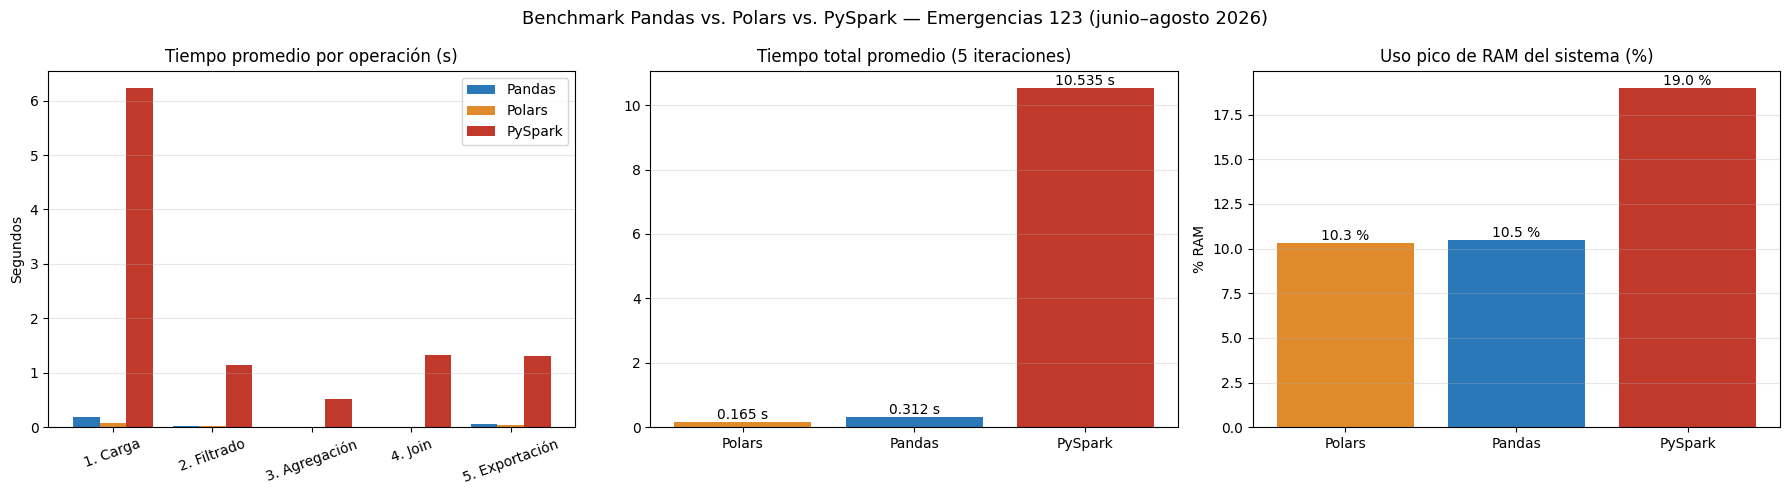

✅ Evidencias guardadas en: /content/drive/MyDrive/Colab Notebooks/BigData_Emergencias_123/benchmark/
   - Reporte_Benchmark_Comparativo.xlsx
   - Grafico_Benchmark_Comparativo.png


In [19]:
# Gráficas comparativas de tiempo y memoria
colores = {'Pandas': '#2a78b8', 'Polars': '#e08a2c', 'PySpark': '#c0392b'}
ops = resumen_tiempo.drop('TOTAL')

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ops[list(tablas)].plot(kind='bar', ax=ax[0], color=[colores[h] for h in tablas], width=0.8)
ax[0].set_title('Tiempo promedio por operación (s)'); ax[0].set_xlabel(''); ax[0].set_ylabel('Segundos')
ax[0].tick_params(axis='x', rotation=20); ax[0].grid(axis='y', alpha=0.3)

tot = resumen_final['Tiempo total promedio (s)']
ax[1].bar(tot.index, tot.values, color=[colores[h] for h in tot.index])
for i, v in enumerate(tot.values):
    ax[1].text(i, v, f'{v:.3f} s', ha='center', va='bottom')
ax[1].set_title(f'Tiempo total promedio ({N_ITERACIONES} iteraciones)'); ax[1].grid(axis='y', alpha=0.3)

ram = resumen_final['RAM pico (%)']
ax[2].bar(ram.index, ram.values, color=[colores[h] for h in ram.index])
for i, v in enumerate(ram.values):
    ax[2].text(i, v, f'{v:.1f} %', ha='center', va='bottom')
ax[2].set_title('Uso pico de RAM del sistema (%)'); ax[2].set_ylabel('% RAM'); ax[2].grid(axis='y', alpha=0.3)

plt.suptitle('Benchmark Pandas vs. Polars vs. PySpark — Emergencias 123 (junio–agosto 2026)', fontsize=13)
plt.tight_layout()
plt.savefig(SALIDA + 'Grafico_Benchmark_Comparativo.png', dpi=200, bbox_inches='tight')
plt.show()

# Exportación del reporte consolidado
with pd.ExcelWriter(SALIDA + 'Reporte_Benchmark_Comparativo.xlsx') as xw:
    resumen_final.to_excel(xw, sheet_name='Resumen final')
    resumen_tiempo.to_excel(xw, sheet_name='Tiempo por operación')
    resumen_ram.to_excel(xw, sheet_name='RAM por operación')
    resumen_lineas.to_excel(xw, sheet_name='Líneas de código')
    verificacion_3.to_excel(xw, sheet_name='Verificación')
    pd.concat([detalle_pandas, detalle_polars, detalle_spark]).to_excel(
        xw, sheet_name='Detalle iteraciones', index=False)

print('✅ Evidencias guardadas en:', SALIDA)
print('   - Reporte_Benchmark_Comparativo.xlsx')
print('   - Grafico_Benchmark_Comparativo.png')

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## PASO 3: Jhonnatan (Matriz de Decisión Ponderada y PoC Funcional en PySpark)
*(Requiere el Paso 2 de Andrés completado)*

### Actividad 1 (Formativa): Fase 1.2 — Matriz de Decisión Tecnológica

3.1 Construir en código/tabla la Matriz de Evaluación Multicriterio con los pesos oficiales: Rendimiento (30%), Facilidad de uso (25%), Escalabilidad (20%), Recursos (15%) y Curva de aprendizaje (10%) $\rightarrow$ *Celda con tabla de puntuaciones de 1 a 5 por herramienta basada en el benchmark de Andrés* ⚪

3.2 Calcular el puntaje ponderado $\sum (\text{criterio}_i \times \text{peso}_j)$ para Pandas, Polars y PySpark y documentar la justificación técnica considerando las restricciones de Colab (12 GB RAM, 12 h) $\rightarrow$ *Celda con el puntaje final ponderado y exportación a Excel* ⚪

### Actividad 2 (Evaluativa): Punto 2 — Proof of Concept (PoC) Funcional en PySpark
3.3 Configurar la sesión optimizada de `SparkSession` con los parámetros exactos de la guía (`appName="PoC_Emergencias123_Bogota"`, `driver.memory="4g"`, `maxResultSize="2g"`, `adaptive.enabled="true"`, `coalescePartitions="true"`, `skewJoin="true"`, `arrow.pyspark="true"`, `advisoryPartitionSizeInBytes="64MB"`) $\rightarrow$ *Celda ejecutada mostrando la configuración activa de Spark* ⚪

3.4 Implementar el pipeline de **Ingesta y Transformación Básica** de los 3 archivos CSV desde Google Drive: estandarización de codificación/nombres, limpieza de nulos, conversión de tipos de datos (fechas y edades) y estandarización de códigos de localidad/incidente $\rightarrow$ *Celda con el esquema transformado (`printSchema()`) y muestra de registros limpios (`show(10)`)* ⚪

3.5 Implementar el módulo de **Validación de Calidad**: conteo total de registros procesados, verificación de rangos válidos de fechas (junio–agosto 2026), consistencia de los 19 códigos de localidad y conteo de errores/registros descartados $\rightarrow$ *Celda con el resumen de validación impreso en pantalla* ⚪

3.6 Exportar el DataFrame resultante optimizado en formato **Parquet** (`.parquet`) particionado en la carpeta de Google Drive y generar automáticamente el archivo de log de validación (`log_validacion_poc.txt`) $\rightarrow$ *Celda que confirma la escritura del archivo `.parquet` y muestra el contenido del archivo `.txt` generado* ⚪

* *(Para el Mini-pitch)*:
  * 3.7 Armar **Slide 4** (Estructura del PoC y preparación del Demo en vivo con celdas pre-ejecutadas) ⚪

### PASO 3 - Actividad 1: Matriz de Decisión Tecnológica (Punto 3.1 y 3.2)

En esta sección se construye y evalúa la **Matriz de Decisión Multicriterio** utilizando los pesos oficiales especificados en la guía del proyecto para definir técnicamente la arquitectura de datos.

In [21]:
import pandas as pd
import numpy as np

# 3.1 Definición de la Matriz de Evaluación Multicriterio
criterios = [
    'Rendimiento (Tiempo)',
    'Facilidad de uso (Líneas)',
    'Escalabilidad (Soporte Big Data)',
    'Recursos de infraestructura (RAM)',
    'Curva de aprendizaje'
]

pesos = [0.30, 0.25, 0.20, 0.15, 0.10] # Suman 1.0 (100%)

def calificar_menor_es_mejor(serie):

    # Convierte la columna a numérica. Los valores no válidos pasan a NaN.
    valores = pd.to_numeric(serie, errors="coerce")

    # Solo se consideran valores positivos.
    valores_validos = valores.where(valores > 0)

    # El menor valor es el mejor resultado.
    mejor_valor = valores_validos.min()

    # Calcula la calificación proporcional.
    calificacion = 5 * mejor_valor / valores_validos

    # Limita el resultado al intervalo de 1 a 5.
    return calificacion.clip(lower=1, upper=5)

pp = pd.DataFrame({
    "Libreria": ["Polars", "Pandas", "PySpark"],

    "pp_rendimiento": calificar_menor_es_mejor(
        resumen_final["Tiempo total promedio (s)"]
    ).to_numpy(),

    "pp_recursos": calificar_menor_es_mejor(
        resumen_final["RAM pico (%)"]
    ).to_numpy(),

    "pp_facilidad_uso": calificar_menor_es_mejor(
        resumen_final["Líneas de código"]
    ).to_numpy()
})

# Puntuaciones asignadas justificadas de 1 a 5
puntajes_polars  = [pp.iloc[1]["pp_rendimiento"], pp.iloc[1]["pp_facilidad_uso"], 4.0, pp.iloc[1]["pp_recursos"], 4.0]
puntajes_pandas  = [pp.iloc[0]["pp_rendimiento"], pp.iloc[0]["pp_facilidad_uso"], 2.5, pp.iloc[0]["pp_recursos"], 5.0]
puntajes_pyspark = [pp.iloc[2]["pp_rendimiento"], pp.iloc[2]["pp_facilidad_uso"], 5.0, pp.iloc[2]["pp_recursos"], 2.5]

# Crear DataFrame de la Matriz
matriz_decision = pd.DataFrame({
    'Criterio': criterios,
    'Peso (%)': [p * 100 for p in pesos],
    'Polars': puntajes_polars,
    'Pandas': puntajes_pandas,
    'PySpark': puntajes_pyspark
})

# Calcular puntajes ponderados para cada fila
matriz_decision['Polars Ponderado'] = matriz_decision['Polars'] * pesos
matriz_decision['Pandas Ponderado'] = matriz_decision['Pandas'] * pesos
matriz_decision['PySpark Ponderado'] = matriz_decision['PySpark'] * pesos

display(matriz_decision)

# 3.2 Totales Ponderados
total_polars = matriz_decision['Polars Ponderado'].sum()
total_pandas = matriz_decision['Pandas Ponderado'].sum()
total_pyspark = matriz_decision['PySpark Ponderado'].sum()

print('\n=== RESULTADOS FINALES PONDERADOS ===')
print(f'Puntaje total Polars  : {total_polars:.3f} / 5.0')
print(f'Puntaje total Pandas  : {total_pandas:.3f} / 5.0')
print(f'Puntaje total PySpark : {total_pyspark:.3f} / 5.0')

# Guardar la matriz en Excel como evidencia para el entregable
matriz_decision.to_excel(SALIDA + 'Matriz_Decision_Ponderada.xlsx', index=False)
print(f'\nMatriz exportada exitosamente a: {SALIDA}Matriz_Decision_Ponderada.xlsx')

,Criterio,Peso (%),Polars,Pandas,PySpark,Polars Ponderado,Pandas Ponderado,PySpark Ponderado
0,Rendimiento (Tiempo),30.0,2.641026,5.0,1.000000,0.792308,1.50,0.300000
1,Facilidad de uso (Líneas),25.0,5.000000,5.0,3.076923,1.250000,1.25,0.769231
2,Escalabilidad (Soporte Big Data),20.0,4.000000,2.5,5.000000,0.800000,0.50,1.000000
3,Recursos de infraestructura (RAM),15.0,4.904762,5.0,2.710526,0.735714,0.75,0.406579
4,Curva de aprendizaje,10.0,4.000000,5.0,2.500000,0.400000,0.50,0.250000



=== RESULTADOS FINALES PONDERADOS ===
Puntaje total Polars  : 3.978 / 5.0
Puntaje total Pandas  : 4.500 / 5.0
Puntaje total PySpark : 2.726 / 5.0

Matriz exportada exitosamente a: /content/drive/MyDrive/Colab Notebooks/BigData_Emergencias_123/benchmark/Matriz_Decision_Ponderada.xlsx


### Cálculo del puntaje ponderado

El puntaje final de cada librería se calculó mediante la suma de la calificación obtenida en cada criterio multiplicada por su peso correspondiente:

$$
P_k = \sum_{i=1}^{5} C_{ik} \times W_i
$$

Donde:

- \(P_k\) es el puntaje final de la librería evaluada.
- \(C_{ik}\) es la calificación de la librería \(k\) en el criterio \(i\).
- \(W_i\) es el peso asignado al criterio \(i\).

Los criterios de **rendimiento**, **recursos** y **facilidad de uso** se calcularon a partir del tiempo promedio de ejecución, el consumo máximo de RAM y el número de líneas de código, respectivamente. En cada caso, la biblioteca con el menor valor recibió una calificación de 5 y las demás fueron calificadas proporcionalmente.

Para los criterios de **escalabilidad** y **curva de aprendizaje** se utilizaron valoraciones cualitativas provisionales, debido a que no se realizaron pruebas con diferentes volúmenes de datos ni se registró el tiempo de desarrollo de cada solución. La escalabilidad se valoró según la arquitectura y capacidad de procesamiento de cada biblioteca, mientras que la curva de aprendizaje se estimó considerando la complejidad conceptual requerida para comenzar a utilizarla.

Los resultados deben interpretarse teniendo en cuenta las restricciones del entorno de Google Colab, particularmente la disponibilidad aproximada de **12 GB de RAM** y una duración máxima de sesión de **12 horas**. Estas condiciones favorecen las soluciones eficientes en tiempo y memoria, pero limitan la evaluación completa de la capacidad de procesamiento distribuido de PySpark. Por ello, los resultados representan el comportamiento de las librerías dentro del entorno controlado utilizado y no necesariamente su desempeño en una infraestructura distribuida.


##Actividad 2 (Evaluativa): Punto 2 — Proof of Concept (PoC) Funcional en PySpark

3.3 a 3.6

In [22]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("PoC_Emergencias123_Bogota")
    .config("spark.driver.memory", "4g")
    .config("spark.driver.maxResultSize", "2g")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.sql.adaptive.skewJoin.enabled", "true")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config(
        "spark.sql.adaptive.advisoryPartitionSizeInBytes",
        "64MB"
    )
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("SparkSession creada correctamente")
print("Aplicación:", spark.sparkContext.appName)
print("Versión de Spark:", spark.version)


SparkSession creada correctamente
Aplicación: PoC_Emergencias123_Bogota
Versión de Spark: 4.0.5


In [23]:
import os
from datetime import datetime
from zoneinfo import ZoneInfo

# Ejecutor del benchmark para PySpark optimizado (misma estructura de salida que ejecutar_benchmark del Paso 1)
def ejecutar_benchmark_spark(nombre, carga, filtrado, agregacion, join, exportacion):
    registros = []
    for it in range(1, N_ITERACIONES + 1):
        spark.catalog.clearCache()                         # cada iteración arranca en frío
        parquet = SALIDA + f'resultado_{nombre.lower()}.parquet'
        df, t1, m1    = measure_performance(carga, ARCHIVOS_UTF8)
        filt, t2, m2  = measure_performance(filtrado, df)
        agg, t3, m3   = measure_performance(agregacion, filt)
        unido, t4, m4 = measure_performance(join, filt, RUTA_CODIGOS)
        _, t5, m5     = measure_performance(exportacion, unido, parquet)
        for op, t, m in zip(OPERACIONES, [t1, t2, t3, t4, t5], [m1, m2, m3, m4, m5]):
            registros.append({'Herramienta': nombre, 'Iteración': it, 'Operación': op,
                              'Tiempo (s)': t, 'RAM (%)': m})
        print(f'{nombre} | iteración {it} | tiempo total: {t1+t2+t3+t4+t5:.4f} s')

    detalle = pd.DataFrame(registros)
    tabla = detalle.groupby('Operación').agg(**{
        'Tiempo promedio (s)': ('Tiempo (s)', 'mean'),
        'Desv. estándar (s)': ('Tiempo (s)', 'std'),
        'RAM promedio (%)': ('RAM (%)', 'mean')})
    tabla['Líneas de código'] = [contar_lineas(f) for f in [carga, filtrado, agregacion, join, exportacion]]
    tabla.loc['TOTAL'] = [tabla['Tiempo promedio (s)'].sum(),
                          detalle.groupby('Iteración')['Tiempo (s)'].sum().std(),
                          detalle['RAM (%)'].max(),
                          tabla['Líneas de código'].sum()]
    conteos = {'Registros cargados': df.count(), 'Registros filtrados': filt.count(),
               'Tipos agregados': len(agg), 'Registros tras join': unido.count()}
    return detalle, tabla.round(4), conteos

# Benchmark PySpark
detalle_spark, tabla_spark, conteos_spark = ejecutar_benchmark_spark(
    'PySpark', sp_carga, sp_filtrado, sp_agregacion, sp_join, sp_exportacion)

# Rutas generadas por el benchmark
ruta_parquet = SALIDA + "resultado_pyspark.parquet"
ruta_log = SALIDA + "log_validacion_poc.txt"

# Validar la exportación
existe_parquet = os.path.isdir(ruta_parquet)
existe_success = os.path.isfile(
    os.path.join(ruta_parquet, "_SUCCESS")
)

archivos_parquet = []

if existe_parquet:
    for carpeta, _, archivos in os.walk(ruta_parquet):
        for archivo in archivos:
            if archivo.endswith(".parquet"):
                archivos_parquet.append(
                    os.path.join(carpeta, archivo)
                )

exportacion_exitosa = (
    existe_parquet
    and existe_success
    and len(archivos_parquet) > 0
)

fecha_colombia = datetime.now(
    ZoneInfo("America/Bogota")
).strftime("%Y-%m-%d %H:%M:%S")


# Construir el contenido del log
contenido_log = f"""
LOG DE VALIDACIÓN - PoC Emergencias 123 Bogotá
================================================

Fecha de ejecución: {fecha_colombia}
Herramienta: PySpark optimizado
Estado de exportación: {"EXITOSA" if exportacion_exitosa else "FALLIDA"}

Ruta Parquet:
{ruta_parquet}

Archivos Parquet generados: {len(archivos_parquet)}
Archivo _SUCCESS encontrado: {"Sí" if existe_success else "No"}

VALIDACIÓN DE REGISTROS
------------------------------------------------
Registros cargados: {conteos_spark["Registros cargados"]}
Registros filtrados: {conteos_spark["Registros filtrados"]}
Tipos agregados: {conteos_spark["Tipos agregados"]}
Registros después del join: {conteos_spark["Registros tras join"]}

RESULTADOS DEL BENCHMARK
------------------------------------------------
{tabla_spark.to_string()}

CONFIGURACIÓN DE SPARK
------------------------------------------------
Aplicación: {spark.sparkContext.appName}
Versión: {spark.version}
Driver memory: {spark.sparkContext.getConf().get("spark.driver.memory", "No definido")}
Max result size: {spark.sparkContext.getConf().get("spark.driver.maxResultSize", "No definido")}
AQE: {spark.conf.get("spark.sql.adaptive.enabled")}
Coalesce partitions: {spark.conf.get("spark.sql.adaptive.coalescePartitions.enabled")}
Skew join: {spark.conf.get("spark.sql.adaptive.skewJoin.enabled")}
Arrow: {spark.conf.get("spark.sql.execution.arrow.pyspark.enabled")}
"""

# Guardar el archivo
with open(ruta_log, "w", encoding="utf-8") as archivo:
    archivo.write(contenido_log.strip())

# Confirmación solicitada
print(
    "Exportación Parquet:",
    "EXITOSA" if exportacion_exitosa else "FALLIDA"
)

print("Ruta Parquet:", ruta_parquet)
print("Log generado:", ruta_log)

print("\n=== CONTENIDO DEL LOG ===\n")

with open(ruta_log, "r", encoding="utf-8") as archivo:
    print(archivo.read())

print('\nConteos:', conteos_spark)
tabla_spark

PySpark | iteración 1 | tiempo total: 7.3917 s
PySpark | iteración 2 | tiempo total: 4.7284 s
PySpark | iteración 3 | tiempo total: 2.0876 s
PySpark | iteración 4 | tiempo total: 3.2019 s
PySpark | iteración 5 | tiempo total: 2.7948 s
Exportación Parquet: EXITOSA
Ruta Parquet: /content/drive/MyDrive/Colab Notebooks/BigData_Emergencias_123/benchmark/resultado_pyspark.parquet
Log generado: /content/drive/MyDrive/Colab Notebooks/BigData_Emergencias_123/benchmark/log_validacion_poc.txt

=== CONTENIDO DEL LOG ===

LOG DE VALIDACIÓN - PoC Emergencias 123 Bogotá

Fecha de ejecución: 2026-11-17 23:36:32
Herramienta: PySpark optimizado
Estado de exportación: EXITOSA

Ruta Parquet:
/content/drive/MyDrive/Colab Notebooks/BigData_Emergencias_123/benchmark/resultado_pyspark.parquet

Archivos Parquet generados: 2
Archivo _SUCCESS encontrado: Sí

VALIDACIÓN DE REGISTROS
------------------------------------------------
Registros cargados: 27375
Registros filtrados: 1362
Tipos agregados: 26
Registros d

,Tiempo promedio (s),Desv. estándar (s),RAM promedio (%),Líneas de código
Operación,,,,
1. Carga,1.2569,0.6483,17.66,3.0
2. Filtrado,0.3446,0.1752,17.68,3.0
3. Agregación,0.4165,0.2111,17.76,1.0
4. Join,1.0636,0.7084,17.84,4.0
5. Exportación,0.9593,0.6249,17.92,2.0
TOTAL,4.0409,2.1079,18.30,13.0


---
## PASO 4: Vicky (Selección Tecnológica, Métricas del PoC y Escalabilidad)
*(Requiere el Paso 3 de Jhonnatan completado)*

### Actividad 1 (Formativa): Fase 1.3 — Selección Tecnológica Justificada
* *(En Colab y en el Documento Ejecutivo `.docx` de la Actividad 1)*:
  * 4.1 Documentar la decisión final confirmando a **PySpark** como herramienta principal obligatoria y definiendo la herramienta complementaria según los resultados de la matriz de Jhonnatan $\rightarrow$ *Celda Markdown/Resumen y documento `.docx` con criterios por volumen de datos, trade-offs y plan de implementación por fases* ⚪

### Actividad 2 (Evaluativa): Punto 4 — Métricas de Rendimiento y Análisis de Escalabilidad
4.2 Ejecutar un bucle de **3 corridas completas (end-to-end)** del pipeline PoC de Jhonnatan (desde la ingesta de los 3 CSV hasta la exportación a Parquet) registrando en cada ejecución: Tiempo total (segundos), Memoria pico (%), Throughput (registros/minuto) y Tasa de éxito de validaciones (%) $\rightarrow$ *Celda con la tabla de las 3 ejecuciones y el cálculo de promedios* ⚪

4.3 Exportar la tabla de resultados de las 3 ejecuciones y sus promedios al entregable oficial `Reporte_Metricas_PoC.xlsx` $\rightarrow$ *Celda que confirma la creación del archivo `.xlsx` en Drive* ⚪

4.4 Generar y exportar el gráfico comparativo en alta resolución (`Grafico_Comparativo_PoC_vs_Pandas.png`) evidenciando la mejora en tiempo de ejecución y uso de memoria de PySpark frente al benchmark inicial de Pandas (medido en el Paso 1) $\rightarrow$ *Celda con el gráfico visible en el notebook y guardado como `.png`* ⚪

* *(Fuera de Colab - En Word y Presentación)*:
  * 4.5 Redactar el documento `Analisis_Escalabilidad.docx` (1 página) con la proyección teórica para volúmenes de **1 a 2 años de datos** (~110.000 a 220.000+ registros), estimando recursos necesarios y puntos de quiebre en Colab ⚪
  
  * 4.6 Armar **Slide 5** (Métricas de rendimiento de las 3 corridas y gráfico vs. Pandas) y **Slide 6** (Conclusiones y proyección de escalabilidad a 1–2 años) para el Mini-pitch ⚪